# Imports

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
 
print("Libraries loaded ")

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Libraries loaded 
/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


# Loading datasets

In [2]:
BASE = '/kaggle/input/competitions/smart-mcq-solver-challenge'
 
train = pd.read_csv(f'{BASE}/train.csv')
test = pd.read_csv(f'{BASE}/test.csv')
sub = pd.read_csv(f'{BASE}/sample_submission.csv')
 
OPTIONS = list('ABCDE')
 
print(f"Train : {train.shape}")
print(f"Test : {test.shape}")
print(f"Sub : {sub.shape}")

Train : (2000, 8)
Test : (500, 7)
Sub : (500, 2)


# EDA

In [3]:
# Datatypes of collumns of all datasets
print("=== TRAIN COLUMNS ===")
print(train.dtypes)
print("\n=== TEST COLUMNS ===")
print(test.dtypes)
print("\n=== SAMPLE SUBMISSION ===")
print(sub.head())

=== TRAIN COLUMNS ===
id         int64
prompt    object
A         object
B         object
C         object
D         object
E         object
answer    object
dtype: object

=== TEST COLUMNS ===
id         int64
prompt    object
A         object
B         object
C         object
D         object
E         object
dtype: object

=== SAMPLE SUBMISSION ===
   ID Prediction
0   1      A B C
1   2      A B C
2   3      A B C
3   4      A B C
4   5      A B C


In [4]:
# First look of data
print("=== TRAIN HEAD ===")
display(train.head(3))
print("\n=== TEST HEAD ===")
display(test.head(3))

=== TRAIN HEAD ===


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C



=== TEST HEAD ===


,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the rel...,"For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p..."
1,2,"What is the estimated redshift of CEERS-93316,...","Approximately z = 6.0, corresponding to 1 bill...","Approximately z = 16.7, corresponding to 235.8...","Approximately z = 3.0, corresponding to 5 bill...","Approximately z = 10.0, corresponding to 13 bi...","Approximately z = 13.0, corresponding to 30 bi..."
2,3,Pick the best possible answer: What is the rea...,The sun appears yellowish due to a reflection ...,"The longer wavelengths of light, such as red a...",The sun appears yellowish due to the scatterin...,The sun emits a yellow light due to its own sp...,The atmosphere absorbs the shorter wavelengths...


In [5]:
# Specific Row look
row = train.iloc[7]
print("PROMPT:", row['prompt'])
for opt in OPTIONS:
    print(f"[{opt}]", row[opt])
print("\nCORRECT ANSWER:", row['answer'])

PROMPT: Select the most accurate option: What is the Liouville density? among the listed options.
[A] The Liouville density is a probability distribution that specifies the probability of finding a particle at a certain position in phase space for a collection of particles.
[B] The Liouville density is a quasiprobability distribution that plays an analogous role to the probability distribution for a quantum particle.
[C] The Liouville density is a bounded probability distribution that is a convenient indicator of quantum-mechanical interference.
[D] The Liouville density is a probability distribution that takes on negative values for states which have no classical model.
[E] The Liouville density is a probability distribution that satisfies all the properties of a conventional probability distribution for a quantum particle.

CORRECT ANSWER: A


In [6]:
#Missing values
print("=== TRAIN — NULL VALUES ===")
print(train.isnull().sum())
print("\n=== TEST — NULL VALUES ===")
print(test.isnull().sum())
# Duplicate check
print(f"Duplicate prompts in train : {train['prompt'].duplicated().sum()}")
print(f"Duplicate prompts in test  : {test['prompt'].duplicated().sum()}")

=== TRAIN — NULL VALUES ===
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

=== TEST — NULL VALUES ===
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
dtype: int64
Duplicate prompts in train : 242
Duplicate prompts in test  : 8


=== ANSWER DISTRIBUTION ===
answer
A    369
B    490
C    459
D    358
E    324
Name: count, dtype: int64


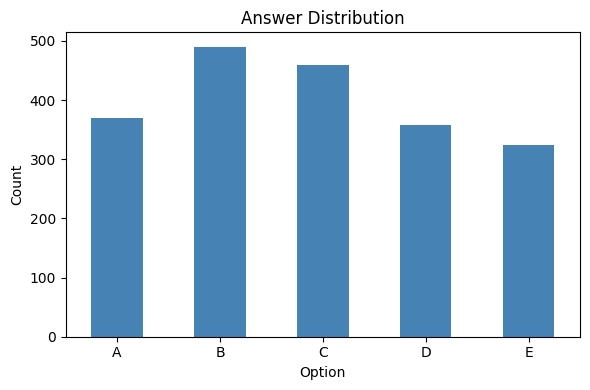

In [7]:
# Answer Distribution visualization
ans_counts = train['answer'].value_counts().sort_index()
print("=== ANSWER DISTRIBUTION ===")
print(ans_counts)

# Barchart demonstration for distributiuon
ans_counts.plot(kind='bar', color='steelblue', figsize=(6,4))
plt.title('Answer Distribution')
plt.xlabel('Option')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

=== PROMPT LENGTH ===
count    2000.0
mean      117.7
std        44.4
min        19.0
25%        87.8
50%       111.0
75%       141.0
max       337.0
Name: prompt, dtype: float64

=== AVERAGE OPTION LENGTH ===
  Option A: 164.1 chars
  Option B: 166.6 chars
  Option C: 167.2 chars
  Option D: 162.6 chars
  Option E: 164.2 chars


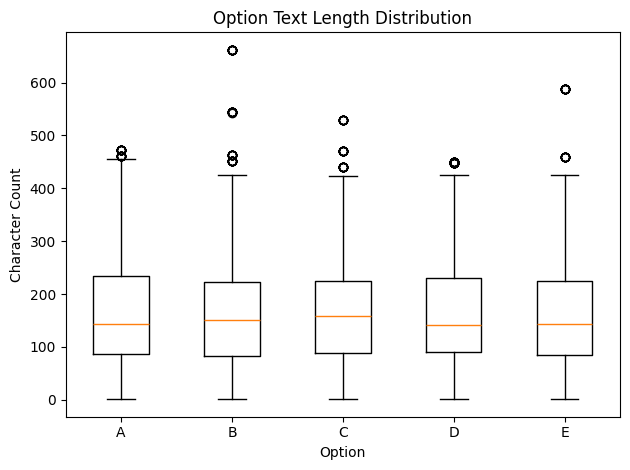

In [8]:
# Text length visualization
print("=== PROMPT LENGTH ===")
print(train['prompt'].str.len().describe().round(1))
print("\n=== AVERAGE OPTION LENGTH ===")
for opt in OPTIONS:
    avg = train[opt].str.len().mean()
    print(f"  Option {opt}: {avg:.1f} chars")

# Box plot of option lengths
length_data = [train[opt].str.len().values for opt in OPTIONS]
plt.boxplot(length_data, labels=OPTIONS)
plt.title('Option Text Length Distribution')
plt.xlabel('Option')
plt.ylabel('Character Count')
plt.tight_layout()
plt.show()

In [9]:
# Word overlap in prompt and correct answer
import re
def word_overlap(prompt, answer_text):
    prompt_words  = set(re.findall(r'\w+', prompt.lower()))
    answer_words  = set(re.findall(r'\w+', answer_text.lower()))
    common = prompt_words & answer_words
    return len(common)

train['correct_option_text'] = train.apply(lambda r: r[r['answer']], axis=1)
train['overlap_correct'] = train.apply(lambda r: word_overlap(r['prompt'], r['correct_option_text']), axis=1)

=== WORD OVERLAP(prompt → correct answer) ===
count    2000.00
mean        5.03
std         3.42
min         0.00
25%         3.00
50%         5.00
75%         7.00
max        18.00
Name: overlap_correct, dtype: float64


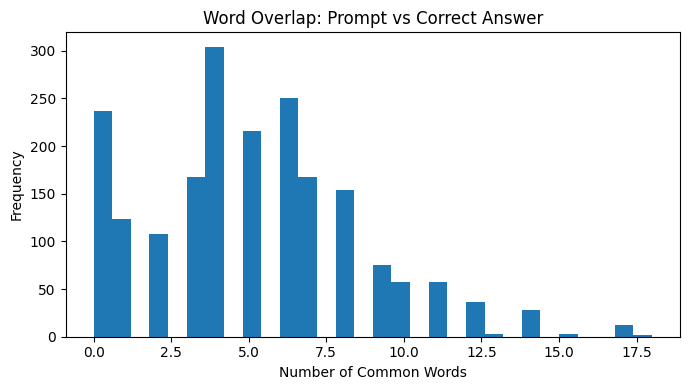

In [10]:
print("=== WORD OVERLAP(prompt → correct answer) ===")
print(train['overlap_correct'].describe().round(2))

train['overlap_correct'].plot(kind='hist', bins=30, figsize=(7,4))
plt.title('Word Overlap: Prompt vs Correct Answer')
plt.xlabel('Number of Common Words')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

=== QUESTION TYPE COUNTS ===
question_type
Other                 605
Pick the best         316
Select                309
Determine             299
Which                 293
What is / What are    169
Who                     7
How                     2
Name: count, dtype: int64


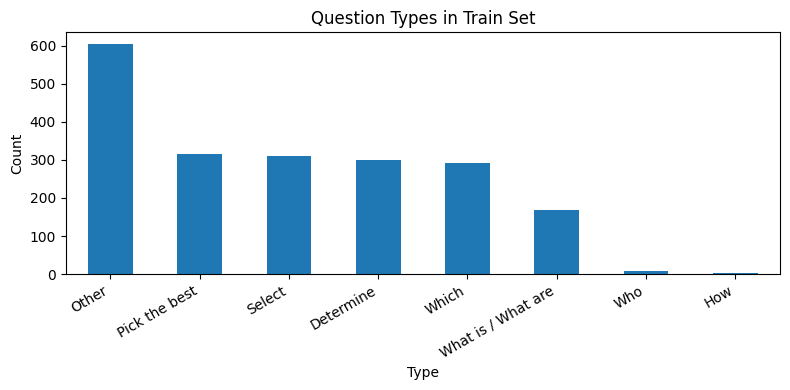

In [11]:
patterns = {
    'What is / What are' : r'^what (is|are)',
    'Which': r'^which',
    'Pick the best': r'^pick',
    'Select': r'^select',
    'Determine': r'^determine',
    'How': r'^how',
    'Why': r'^why',
    'Who': r'^who',
    'When': r'^when',
    'Other': None
}

def get_question_type(prompt):
    p = prompt.lower().strip()
    for label, pattern in patterns.items():
        if pattern and re.match(pattern, p):
            return label
    return 'Other'

train['question_type'] = train['prompt'].apply(get_question_type)
print("=== QUESTION TYPE COUNTS ===")
print(train['question_type'].value_counts())

train['question_type'].value_counts().plot(kind='bar', figsize=(8,4))
plt.title('Question Types in Train Set')
plt.xlabel('Type')
plt.ylabel('Count')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [12]:
sub.to_csv('submission.csv', index=False)